In [2]:
import pandas as pd
import numpy as np
df = pd.read_csv("semillas_dataset.csv") # Cargar el dataset
df.head() # Ver las primeras filas

,Area,Perimeter,Compactness,Kernel_Length,Kernel_Width,Asymmetry_Coeff,Kernel_Groove_Length,Class
0,16.50,16.66,0.8807,6.14,3.74,4.44,6.04,2
1,13.23,13.20,0.8926,5.72,3.09,3.63,4.93,1
2,20.54,16.86,0.9098,6.30,3.64,3.84,6.43,2
3,13.84,14.29,0.9098,5.72,2.91,2.83,5.67,1
4,16.34,14.43,0.8585,5.33,3.08,1.02,5.36,1


In [3]:
print("Forma:", df.shape) # Filas y columnas
print("Columnas:", list(df.columns)) # Nombres de columnas
df.info() # Tipos de datos y no nulos
print(df.isnull().sum()) # Nulos por columna

Forma: (210, 8)
Columnas: ['Area', 'Perimeter', 'Compactness', 'Kernel_Length', 'Kernel_Width', 'Asymmetry_Coeff', 'Kernel_Groove_Length', 'Class']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 210 entries, 0 to 209
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Area                  210 non-null    float64
 1   Perimeter             210 non-null    float64
 2   Compactness           210 non-null    float64
 3   Kernel_Length         210 non-null    float64
 4   Kernel_Width          210 non-null    float64
 5   Asymmetry_Coeff       210 non-null    float64
 6   Kernel_Groove_Length  210 non-null    float64
 7   Class                 210 non-null    int64  
dtypes: float64(7), int64(1)
memory usage: 13.3 KB
Area                    0
Perimeter               0
Compactness             0
Kernel_Length           0
Kernel_Width            0
Asymmetry_Coeff         0
Kernel_Groove_Length    0
Class

In [4]:
from sklearn.preprocessing import StandardScaler # Importa el normalizador

X = df.drop("Class", axis=1) # Variables predictoras (7 columnas)
y = df["Class"] # Variable objetivo

scaler = StandardScaler() # Crea el normalizador
X_scaled = scaler.fit_transform(X) # Normaliza (media 0, desviación 1)
X_scaled = pd.DataFrame(X_scaled, columns=X.columns) # Lo vuelve a tabla

print(X_scaled.mean().round(2)) # Medias (deben ser ~0)
print(X_scaled.std().round(2)) # Desviaciones (deben ser ~1)

Area                   -0.0
Perimeter              -0.0
Compactness             0.0
Kernel_Length          -0.0
Kernel_Width            0.0
Asymmetry_Coeff        -0.0
Kernel_Groove_Length   -0.0
dtype: float64
Area                    1.0
Perimeter               1.0
Compactness             1.0
Kernel_Length           1.0
Kernel_Width            1.0
Asymmetry_Coeff         1.0
Kernel_Groove_Length    1.0
dtype: float64


In [5]:
v1 = np.array([2, 3, 4]) # Vector 1
v2 = np.array([1, 5, 2]) # Vector 2
print("Producto punto:", np.dot(v1, v2)) # v1 · v2
print("Norma de v1:", np.linalg.norm(v1)) # Longitud del vector v1

A = np.array([[2, 1], [1, 3]]) # Matriz de coeficientes
b = np.array([8, 13]) # Términos independientes
sol = np.linalg.solve(A, b) # Resuelve A·x = b
print("Solución (x, y):", sol)
print("Verificación:", np.dot(A, sol)) # Debe dar [8, 13]

Producto punto: 25
Norma de v1: 5.385164807134504
Solución (x, y): [2.2 3.6]
Verificación: [ 8. 13.]


In [6]:
for col in ["Area", "Perimeter"]: # Recorre las dos variables
    print(col, "| Media:", round(df[col].mean(), 4), "| Mediana:", round(df[col].median(), 4),
          "| Varianza:", round(np.var(df[col]), 4), "| Desv. estándar:", round(np.std(df[col]), 4)) # Con NumPy

def varianza_manual(datos): # Varianza poblacional sin NumPy
    n = len(datos) # Cantidad de datos
    media = sum(datos) / n # Media calculada a mano
    return sum((x - media) ** 2 for x in datos) / n # Promedio de las diferencias al cuadrado

def desviacion_manual(datos): # Desviación estándar sin NumPy
    return varianza_manual(datos) ** 0.5 # Raíz de la varianza

area = df["Area"].tolist() # Area como lista
print("\nVarianza manual:", varianza_manual(area), "| NumPy:", np.var(area)) # Comparación
print("Desviación manual:", desviacion_manual(area), "| NumPy:", np.std(area)) # Comparación

Area | Media: 14.7044 | Mediana: 14.115 | Varianza: 7.559 | Desv. estándar: 2.7494
Perimeter | Media: 14.596 | Mediana: 14.375 | Varianza: 1.8562 | Desv. estándar: 1.3624

Varianza manual: 7.558962712018141 | NumPy: 7.558962712018141
Desviación manual: 2.749356781506929 | NumPy: 2.749356781506929


In [7]:
media = df["Area"].mean() # Media de Area
std = df["Area"].std() # Desviación estándar de Area
limite_inf = media - 2 * std # Límite inferior
limite_sup = media + 2 * std # Límite superior
print("Límites:", round(limite_inf, 4), "a", round(limite_sup, 4))

atipicos = df[(df["Area"] < limite_inf) | (df["Area"] > limite_sup)] # Filas fuera de los límites
print("Cantidad de atípicos:", len(atipicos))
atipicos # Muestra las filas atípicas

Límites: 9.1925 a 20.2162
Cantidad de atípicos: 4


,Area,Perimeter,Compactness,Kernel_Length,Kernel_Width,Asymmetry_Coeff,Kernel_Groove_Length,Class
2,20.54,16.86,0.9098,6.30,3.64,3.84,6.43,2
11,20.65,16.75,0.8671,5.64,3.61,2.83,6.25,2
34,20.43,15.90,0.8876,5.96,3.71,2.95,6.19,2
42,20.33,15.52,0.8635,6.30,3.71,3.21,6.18,2


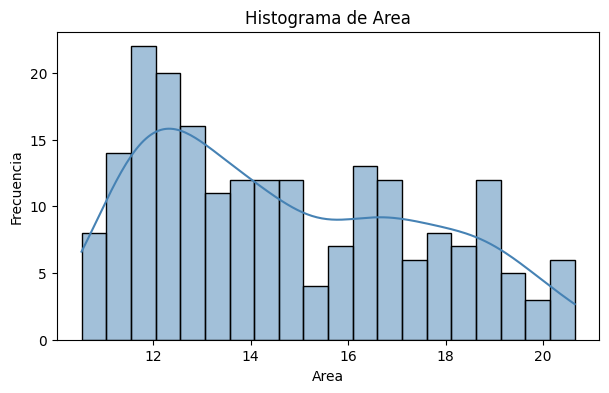

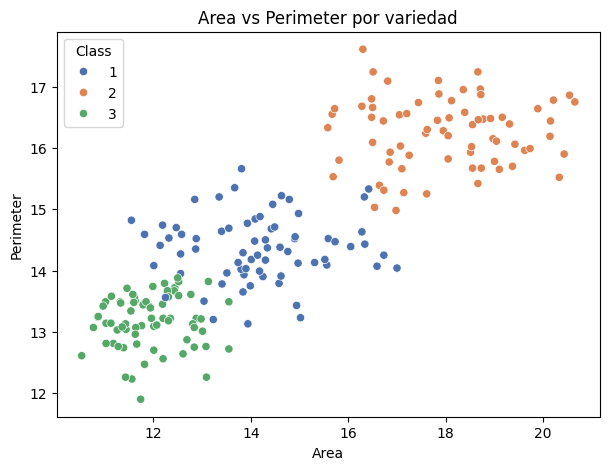

In [8]:
import matplotlib.pyplot as plt # Librería de gráficos
import seaborn as sns # Librería de gráficos estadísticos

plt.figure(figsize=(7, 4)) # Tamaño de la figura
sns.histplot(df["Area"], bins=20, kde=True, color="steelblue") # Histograma con curva de densidad
plt.title("Histograma de Area") # Título
plt.xlabel("Area") # Etiqueta eje X
plt.ylabel("Frecuencia") # Etiqueta eje Y
plt.show() # Muestra el gráfico

plt.figure(figsize=(7, 5)) # Tamaño de la figura
sns.scatterplot(data=df, x="Area", y="Perimeter", hue="Class", palette="deep") # Colores por variedad
plt.title("Area vs Perimeter por variedad") # Título
plt.show() # Muestra el gráfico

In [9]:
from sklearn.model_selection import train_test_split # Separa datos en entrenamiento y prueba
from sklearn.neighbors import KNeighborsClassifier # Modelo K-Vecinos
from sklearn.tree import DecisionTreeClassifier # Modelo Árbol de Decisión
from sklearn.metrics import accuracy_score # Métrica Accuracy

X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42, stratify=y) # 80% entrenamiento, 20% prueba

knn = KNeighborsClassifier(n_neighbors=5) # Crea KNN con 5 vecinos
knn.fit(X_train, y_train) # Entrena KNN
acc_knn = accuracy_score(y_test, knn.predict(X_test)) # Accuracy de KNN

arbol = DecisionTreeClassifier(random_state=42) # Crea el árbol
arbol.fit(X_train, y_train) # Entrena el árbol
acc_arbol = accuracy_score(y_test, arbol.predict(X_test)) # Accuracy del árbol

print("Accuracy KNN:", round(acc_knn, 4)) # Resultado KNN
print("Accuracy Árbol:", round(acc_arbol, 4)) # Resultado árbol

Accuracy KNN: 1.0
Accuracy Árbol: 0.9524
